# Install Ollama and run , Install all dependencies

In [2]:
!apt-get install zstd
!curl -fsSL https://ollama.com/install.sh | sh

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 53 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (6,916 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122403 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Add

In [ ]:
# Starte Ollam a server and download model
import subprocess

ollama_prs = subprocess.Popen(["ollama","serve"],
                              stdout=subprocess.PIPE,
                              stderr=subprocess.PIPE)

# Install all dependecies for langraph
!pip install langchain
!pip install langchain-core
!pip install langchain-community
!pip install langchain-ollama
!pip install langgraph

# Download model
!ollama pull llama3.2:1b




In [4]:
#Show avialable model in Ollama
!ollama list

NAME           ID              SIZE      MODIFIED       
llama3.2:1b    baf6a787fdff    1.3 GB    27 seconds ago    


In [17]:
!ollama run llama3.2:1b "Hello"

Hello! How can I assist you today?



# Langgraph

    State
    LLM
    Node
    Edge
    

In [5]:
# Create a state
from pydantic import BaseModel

class AgentState(BaseModel):
  question : str
  answer : str = None


In [8]:
# Create LLM object for graph Nodes
from langchain_ollama import ChatOllama
llm = ChatOllama(model="llama3.2:1b")

In [9]:
# Create Node using function
def chatbot(state : AgentState):
  question = state.question
  answer = llm.invoke(question)
  state.answer = answer.content
  return state


In [11]:
# Build Graph using State, Nodes and edge
from langgraph.graph import StateGraph, END

# Set state for a graph
builder = StateGraph(AgentState)

# add nodes to graph
builder.add_node("Cnode", chatbot)

# Add edges
builder.add_edge("Cnode", END)

# set entry point 1st node to start the graph
builder.set_entry_point("Cnode")

# Compile the graph
graph = builder.compile()


In [12]:
graph.get_graph().draw_mermaid()

'---\nconfig:\n  flowchart:\n    curve: linear\n---\ngraph TD;\n\t__start__([<p>__start__</p>]):::first\n\tCnode(Cnode)\n\t__end__([<p>__end__</p>]):::last\n\t__start__ --> Cnode;\n\tCnode --> __end__;\n\tclassDef default fill:#f2f0ff,line-height:1.2\n\tclassDef first fill-opacity:0\n\tclassDef last fill:#bfb6fc\n'

In [13]:
graph.get_graph().draw_mermaid_png()

b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x00j\x00\x00\x00\xea\x08\x02\x00\x00\x00\xc5\xf3G\x18\x00\x00\x10\x00IDATx\x9c\xec\x9d\x07xTU\xda\xc7\xcf\xbdwZ\xda\xa4\x0fi\xa4CB\x91\x1aJhQ\tE\xd6H\xc0\xec\xc2R>\x0b\xae\x80 Ep?\x15t\x1f\x04>vWQ\\\x16\x16,\x08*\x08\n\x02YP\x8a\x02\xd1\xd0!\xa1\x84\x80\x92\x84\x14B\n\xc9$3\x99\x92)\xf7\xcewf&L\xda\xcd\xcc\xdc\x9c\x0c^\x92\xf3{`\x9e\xcc)wf\xfe\xf7\x94\xf7\x9e\xf6\nL&\x13\xc0\xb4\x17\x01\xc0 \x80\xe5C\x02\xcb\x87\x04\x96\x0f\t,\x1f\x12X>$P\xe5\xbb\x93S\x9fwE\xa9\x90\x1b\x8czF\xa7a@s+\x88 M&\x86h\x91\x85\xa0L&\xbaY\xa0\x89\x04\x04\xd3\xf2\xca\x04\t\xff\x03\x13\xdd<\x944\x81V\x17\x84\xd9aZS\xab+\xb0&\x86\x08$\xa4XB\xba{Q\x11\xbd<\xfa$z\x01\x04\x88\xf6\xd9}Y\'\x14\xd7N\xd7j\x94F\xc0\x00\xa1\x90\x14\xb8\x11b\tE\xd3\x8c\x89n~5\xf8\xb3Z\xeb" L\xc6f\xc9\x08\x9201-\xbf\x86Y>\xd2\xc9\x94P#\x13\x9b|,\x9f\x0e\x11\x8a)\xdah\xd2\xd5\xd3\x06\x1d\xc3\xd0&\x89\xa70\xaa\xb7\xc7\x13\x7f\n\x00\xdc\xe1,_\xf6O\xcaK\'\xaai\xda\x14\x18*\x19\x92\xec\x1f\xdeK\x0c\x1

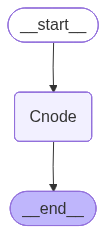

In [14]:
# Visualize the graph
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
# invoke a graph
state = AgentState(question="Explain Transformer")

result = graph.invoke(state)
print(result)

{'question': 'Exaplin Transformer', 'answer': 'Transformer is a revolutionary algorithm introduced by Vaswani et al. in their paper "Attention is All You Need" at NIPS 2017. It\'s a fundamental building block for many state-of-the-art neural network architectures, including transformer-based models.\n\n**What is the Transformer?**\n\nThe Transformer architecture is a sequence-to-sequence model that allows input sequences to be processed as if they were an output sequence. This enables it to handle long-range dependencies and contextual relationships in text or other sequential data.\n\n**Key Components:**\n\n1. **Embeddings**: Represent each token (word or character) in the input sequence with a vector of fixed size.\n2. **Encoder**: The encoder consists of multiple layers, each applying a different operation:\n\t* **Self-Attention Mechanism**: allows the model to attend to different parts of the input sequence simultaneously and weigh their importance.\n\t* **Layer Normalization**: no

In [18]:
type(result)

dict

In [19]:
result

{'question': 'Exaplin Transformer',
 'answer': 'Transformer is a revolutionary algorithm introduced by Vaswani et al. in their paper "Attention is All You Need" at NIPS 2017. It\'s a fundamental building block for many state-of-the-art neural network architectures, including transformer-based models.\n\n**What is the Transformer?**\n\nThe Transformer architecture is a sequence-to-sequence model that allows input sequences to be processed as if they were an output sequence. This enables it to handle long-range dependencies and contextual relationships in text or other sequential data.\n\n**Key Components:**\n\n1. **Embeddings**: Represent each token (word or character) in the input sequence with a vector of fixed size.\n2. **Encoder**: The encoder consists of multiple layers, each applying a different operation:\n\t* **Self-Attention Mechanism**: allows the model to attend to different parts of the input sequence simultaneously and weigh their importance.\n\t* **Layer Normalization**: n